# Topic Modeling — Philippine Educational System

This notebook finds the main discussion topics in our dataset of posts and comments about the Philippine educational system.

**Models**
1. **LDA (Latent Dirichlet Allocation)** is the main model.
2. **LSA (Latent Semantic Analysis)** is a comparison model.
3. **BERTopic** is a comparison model that uses multilingual sentence embeddings, so it can handle English, Tagalog, and Taglish.

**Choosing the number of topics (k):** We train LDA for k = 3 to 10 using 5 random seeds each, then compare the average **C_v coherence**, **topic diversity**, and **perplexity**. Because coherence is noisy on a small dataset, we use the **one-standard-error rule**: pick the smallest k whose average coherence is within one standard deviation of the best k. Then we check that its topics are readable.

**Before running:** Upload `Training data (90%).csv` to the Colab Files panel (`/content/`). If you also upload `Unseen Data (10%).csv`, the notebook assigns topics to the holdout records too, so the sentiment analysis can use them later.

**Run order:** Runtime → Run all. If Colab asks you to restart after the installs, restart and run all again.

In [ ]:
# Install libraries that are not preinstalled in Colab.
# gensim 4.4+ works with the numpy 2.x that Colab uses.
!pip install -q "gensim>=4.4.0" bertopic pyLDAvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 27.9 MB/s eta 0:00:00


## Step 1 — Import libraries and fix random seeds
We fix the seeds so everyone in the group gets the same results when they re-run the notebook.

In [ ]:
import os, re, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from gensim.corpora import Dictionary
from gensim.models import LdaModel, LsiModel, TfidfModel, CoherenceModel
from gensim.models.phrases import Phrases, Phraser
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

import nltk
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
from nltk.stem import WordNetLemmatizer

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## Step 2 — Load the dataset
We use the same 90% training file as the similarity analysis. The 10% unseen file is optional and is only used to assign topics to unseen records at the end.

In [ ]:
import glob

def find_file(patterns):
    # Finds the uploaded file even if Colab renamed it (e.g. "Training data (90%) (1).csv")
    for pattern in patterns:
        matches = sorted(glob.glob(pattern))
        if matches:
            return matches[0]
    return None

TRAIN_PATH   = "/content/Training data (90%).csv"
HOLDOUT_PATH = "/content/Unseen Data (10%).csv"   # optional
assert TRAIN_PATH, "Upload 'Training data (90%).csv' to /content first."
print("Training file:", TRAIN_PATH)
print("Unseen file:  ", HOLDOUT_PATH)

df = pd.read_csv(TRAIN_PATH)
print("Training records loaded:", len(df))

holdout_df = pd.read_csv(HOLDOUT_PATH) if HOLDOUT_PATH else None
print("Holdout records loaded:", 0 if holdout_df is None else len(holdout_df))

display(df[["record_id", "record_type", "platform", "keyword", "title", "text"]].head())

Training file: /content/Training data (90%).csv
Unseen file:   /content/Unseen Data (10%).csv
Training records loaded: 180
Holdout records loaded: 20


,record_id,record_type,platform,keyword,title,text
0,data00102,article,web,NaN,deped to launch digital safety campaign after banga school shooting,p99-b budget amendments questionable a director and filmmaker from toronto canada has finally learned why he had a g...
1,data16065,youtube_comment,youtube,education assessment philippines,let reviewer assessment of learning,thanks po sa drills
2,data00641,tiktok_video,tiktok,online learning philippines,pagbabaklas ng balag ng sitaw magkano ang aming bayad,pagbabaklas ng balag ng sitaw magkano ang aming bayad
3,data00014,article,web,NaN,angara pinangunahan ang mass oath-taking ng bagong promoted na guro sa davao region,lungsod ng davao oktubre pinangunahan ni education secretary sonny angara ang mass oath-taking ng pampublikong guro ...
4,data00299,reddit_comment,reddit,philippine education,nakakalungkot talaga ang lagay ng edukasyon sa pilipinas sa kamay ng mga ganitong guro,dito na nagkakamali ang karamihan sa mga teachers natin hindi pwedeng mabait lang ang bata kailangan may alam din hi...


## Step 3 — Build the text to model
We use the same rule as the similarity notebook so the analyses stay consistent:
- **Comments** (YouTube, Reddit): the comment text only. Using the parent video or post title would make every comment under one video look the same.
- **Articles and Reddit posts**: their own title.
- **Everything else** (e.g., TikTok): the text field.

Records with empty text are removed because they have no words to assign to a topic.

In [ ]:
def get_analysis_text(row):
    if row["record_type"] in ["youtube_comment", "reddit_comment"]:
        value = row["text"]
    elif row["record_type"] in ["article", "reddit_post"]:
        value = row["title"]
    else:
        value = row["text"]
    return "" if pd.isna(value) else str(value).strip()

def add_analysis_text(frame):
    frame = frame.copy()
    frame["analysis_text"] = frame.apply(get_analysis_text, axis=1)
    return frame

df = add_analysis_text(df)
empty = (df["analysis_text"] == "").sum()
df = df[df["analysis_text"] != ""].reset_index(drop=True)
print(f"Removed {empty} empty records -> {len(df)} records remain")

if holdout_df is not None:
    holdout_df = add_analysis_text(holdout_df)
    holdout_df = holdout_df[holdout_df["analysis_text"] != ""].reset_index(drop=True)

Removed 2 empty records -> 178 records remain


## Step 4 — Preprocess the text for topic modeling
1. Lowercase the text, then remove URLs, mentions, hashtags symbols, emojis, numbers, and punctuation.
2. Remove **English stopwords**, **Tagalog/Taglish stopwords** (*ang, ng, sa, mga, po, lang, naman, yung…*), and **domain words** that appear almost everywhere (*philippines, education, edukasyon…*). Those words would show up in every topic and wouldn't tell the topics apart.
3. Lemmatize English words (*teachers → teacher*). Tagalog words are left unchanged.
4. Join frequent word pairs into **bigrams** (e.g., `online_learning`, `tuition_fee`).

The stopword lists are editable. If a word with no meaning keeps showing up in the topics, add it to `DOMAIN_STOPWORDS` and re-run.

In [ ]:
TAGALOG_STOPWORDS = set('''
akin aking ako alin amin aming ang ano anumang apat at atin ating ay bago bakit bawat bilang dahil dalawa dapat din rin
dito doon gagawin gayunman ginagawa ginawa ginawang gumawa gusto habang hanggang hindi huwag iba ibaba ibabaw ibig ikaw
ilagay ilalim ilan inyong isa isang itaas ito iyo iyon iyong ka kahit kailangan kailanman kami kanila kanilang kanino
kanya kanyang kapag kapwa karamihan katulad kaya kaysa ko kong kulang kumuha kung laban lahat lamang likod lima maaari
maaaring maging makita marami masyado may mayroon meron mga minsan mismo mula muli na naging nagkaroon nais nakita namin
napaka narito nasaan ng nang ngayon ni nila nilang nito niya niyang noon o pa paano pagitan pagkatapos pamamagitan
para paraan pareho pero sa saan sabi sabihin sarili sila sino siya sya tayo tulad tungkol una wala walang po opo lang
naman talaga yung yun ung un nga ba eh kasi sana daw raw pala muna kayo natin mo nyo niyo dun jan diyan dyan ganun
ganon ganito parang tapos diba ha ah oh hehe haha hahaha lol ok okay pag nag mag ma pa lng nalang na lang ganyan
kami kayo sakin sayo samin satin dyan andun andito dati ngayong kanina mismo lalo talagang naman syempre siguro
'''.split())

EXTRA_ENGLISH_STOPWORDS = set('''
im dont just like really get got also would could lot thing things yeah yes thats youre cant didnt doesnt isnt ive
know think want make going say said dont us u ur pls please thank thanks sir maam mam
'''.split())

# Words that appear in almost every record because of how we searched (our search keywords were about
# schools, students and teachers), plus filler words that showed up in every topic. Edit this list as needed.
DOMAIN_STOPWORDS = set('''
philippines philippine pilipinas ph filipino filipinos education edukasyon video watch subscribe channel
fyp foryou foryoupage viral trending tiktok dontletthisflop xybca
school student teacher yan let actually real time year good start day people
'''.split())

STOPWORDS = set(ENGLISH_STOP_WORDS) | TAGALOG_STOPWORDS | EXTRA_ENGLISH_STOPWORDS | DOMAIN_STOPWORDS
lemmatizer = WordNetLemmatizer()
try:
    lemmatizer.lemmatize("teachers")
except LookupError:
    print("WordNet not available; continuing without lemmatization.")
    class _NoLemma:
        def lemmatize(self, w): return w
    lemmatizer = _NoLemma()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)      # URLs
    text = re.sub(r"[@#]\w+", " ", text)               # mentions / hashtags
    text = re.sub(r"\bu[0-9a-f]{4}\b|\bud[0-9a-f]{2,3}\b", " ", text)  # leftover escaped emoji codes (e.g. ud83c, uddf)
    text = re.sub(r"[^a-zñ\s]", " ", text)             # emojis, numbers, punctuation
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text):
    tokens = []
    for word in clean_text(text).split():
        if len(word) < 3 or word in STOPWORDS:
            continue
        word = lemmatizer.lemmatize(word)              # English nouns; Tagalog words pass through unchanged
        if word not in STOPWORDS:
            tokens.append(word)
    return tokens

df["tokens_tm"] = df["analysis_text"].apply(tokenize)

# Bigrams: join word pairs that appear together often
bigram = Phraser(Phrases(df["tokens_tm"], min_count=3, threshold=5))
df["tokens_tm"] = df["tokens_tm"].apply(lambda t: bigram[t])

# Records left with fewer than 2 tokens carry too little information to assign a topic
MIN_TOKENS = 2
short = (df["tokens_tm"].str.len() < MIN_TOKENS).sum()
df_tm = df[df["tokens_tm"].str.len() >= MIN_TOKENS].reset_index(drop=True)
print(f"Records with < {MIN_TOKENS} tokens after cleaning: {short}")
print(f"Records used for topic modeling: {len(df_tm)}")
print("Bigrams found:", sorted({t for doc in df_tm['tokens_tm'] for t in doc if '_' in t})[:30])

display(df_tm[["record_id", "analysis_text", "tokens_tm"]].head(10))

Records with < 2 tokens after cleaning: 12
Records used for topic modeling: 166
Bigrams found: ['critical_thinking', 'graham_number']


,record_id,analysis_text,tokens_tm
0,data00102,deped to launch digital safety campaign after banga school shooting,"[deped, launch, digital, safety, campaign, banga, shooting]"
1,data00641,pagbabaklas ng balag ng sitaw magkano ang aming bayad,"[pagbabaklas, balag, sitaw, magkano, bayad]"
2,data00014,angara pinangunahan ang mass oath-taking ng bagong promoted na guro sa davao region,"[angara, pinangunahan, mass, oath, taking, bagong, promoted, guro, davao, region]"
3,data00299,dito na nagkakamali ang karamihan sa mga teachers natin hindi pwedeng mabait lang ang bata kailangan may alam din hi...,"[nagkakamali, pwedeng, mabait, bata, alam, pwedeng, mabait, alam, pwedeng, matalino, hambog, literal, kakainin, yang..."
4,data00474,deped approved vacation leave,"[deped, approved, vacation, leave]"
5,data00328,can you tell me some of the universities is clsu apart of that list of universities with good quality education,"[tell, university, clsu, apart, list, university, quality]"
6,data13436,that teacher is a gift from god he has a purpose in life by providing education to the less fortunate my dad told me...,"[gift, god, purpose, life, providing, fortunate, dad, told, important, need, cherish, afford, away]"
7,data00329,i remember my aunt telling me a story about how when my mom got into a state university in a major city my grandfath...,"[remember, aunt, telling, story, mom, state, university, major, city, grandfather, party, entire, street, enrolled, ..."
8,data00298,i think people are being overly critical in his statement my point naman siya may mga matatalinong morally bankrupt ...,"[overly, critical, statement, point, matatalinong, morally, bankrupt, course, ayaw, mabait, saksakan, agnat, medyo, ..."
9,data13049,sayang ka gagraduate lang ng anak ko sa sti multi media arts unifast grantee pero at the end of the day i owe them 8...,"[sayang, gagraduate, anak, sti, multi, medium, art, unifast, grantee, end, owe, buti, half, nabayaran, natanggap, an..."


In [ ]:
# Build the dictionary (vocabulary) and bag-of-words corpus.
# no_below=2  -> drop words that appear in only 1 record (they cannot form a shared topic)
# no_above=0.5 -> drop words that appear in more than half of the records (too general)
texts = df_tm["tokens_tm"].tolist()
dictionary = Dictionary(texts)
print("Vocabulary before filtering:", len(dictionary))
dictionary.filter_extremes(no_below=2, no_above=0.5)
print("Vocabulary after filtering: ", len(dictionary))

corpus = [dictionary.doc2bow(doc) for doc in texts]

# Records whose words were all filtered out cannot be assigned a meaningful topic, so we drop them
has_words = [len(bow) > 0 for bow in corpus]
print("Records with no words left in the vocabulary (dropped):", has_words.count(False))
df_tm = df_tm[has_words].reset_index(drop=True)
texts = df_tm["tokens_tm"].tolist()
corpus = [dictionary.doc2bow(doc) for doc in texts]
print("Final number of records for topic modeling:", len(df_tm))

word_freq = pd.Series({dictionary[i]: f for i, f in dictionary.cfs.items()}).sort_values(ascending=False)
print("\nTop 25 words in the corpus:")
display(word_freq.head(25).to_frame("frequency").T)

Vocabulary before filtering: 1564
Vocabulary after filtering:  375
Records with no words left in the vocabulary (dropped): 14
Final number of records for topic modeling: 152

Top 25 words in the corpus:


,teaching,exam,life,learning,deped,country,university,class,number,college,...,use,private,help,problem,best,critical_thinking,taught,experience,subject,educational
frequency,15,13,13,13,13,13,12,12,12,10,...,8,8,7,7,7,7,7,7,7,7


## Step 5 — Choosing the number of topics (k) for LDA
We train LDA for **k = 3 to 10**. Each k is trained with **5 random seeds**, because LDA results change from run to run and we want an average rather than one lucky run.

| Metric | What it measures | Better |
|---|---|---|
| **C_v coherence** | Whether a topic's top words actually appear together in the records (main metric) | Higher |
| **UMass coherence** | Another co-occurrence measure, based on document counts | Closer to 0 |
| **Perplexity** | How well the model predicts the words | Lower, but it often favors topics people can't interpret, so we only use it as support |
| **Topic diversity** | Share of unique words among all topics' top-10 words; a low value means topics repeat each other | Higher |

In [ ]:
K_RANGE = range(3, 11)
SEEDS = [42, 7, 123, 2024, 99]
TOPN = 10

def train_lda(k, seed):
    return LdaModel(corpus=corpus, id2word=dictionary, num_topics=k,
                    random_state=seed, passes=20, iterations=400,
                    alpha="auto", eta="auto", chunksize=len(corpus))

def top_words(model, k, topn=TOPN):
    return [[w for w, _ in model.show_topic(t, topn=topn)] for t in range(k)]

def coherence(topics, measure):
    return CoherenceModel(topics=topics, texts=texts, dictionary=dictionary,
                          corpus=corpus, coherence=measure, processes=1).get_coherence()

def diversity(topics):
    words = [w for t in topics for w in t]
    return len(set(words)) / len(words)

rows = []
for k in K_RANGE:
    for seed in SEEDS:
        lda = train_lda(k, seed)
        topics = top_words(lda, k)
        rows.append({
            "k": k, "seed": seed,
            "c_v": coherence(topics, "c_v"),
            "u_mass": coherence(topics, "u_mass"),
            "perplexity": np.exp2(-lda.log_perplexity(corpus)),
            "diversity": diversity(topics),
        })
    print(f"k={k} done")

k_runs = pd.DataFrame(rows)
k_summary = (k_runs.groupby("k")
             .agg(c_v_mean=("c_v", "mean"), c_v_std=("c_v", "std"),
                  u_mass_mean=("u_mass", "mean"),
                  perplexity_mean=("perplexity", "mean"),
                  diversity_mean=("diversity", "mean"))
             .round(4))
display(k_summary)

k=3 done
k=4 done
k=5 done
k=6 done
k=7 done
k=8 done
k=9 done
k=10 done


,c_v_mean,c_v_std,u_mass_mean,perplexity_mean,diversity_mean
k,,,,,
3,0.4724,0.0414,-12.7696,68.3966,0.9267
4,0.4522,0.0155,-11.8832,71.7507,0.8650
5,0.4274,0.0281,-13.2008,75.7038,0.8640
6,0.4128,0.0225,-12.8077,77.9566,0.8767
7,0.3983,0.0295,-12.6217,80.7558,0.8714
8,0.4345,0.0401,-11.8643,82.0679,0.8525
9,0.4195,0.0265,-12.8955,85.1553,0.8400
10,0.4361,0.0188,-12.0407,87.4779,0.8100


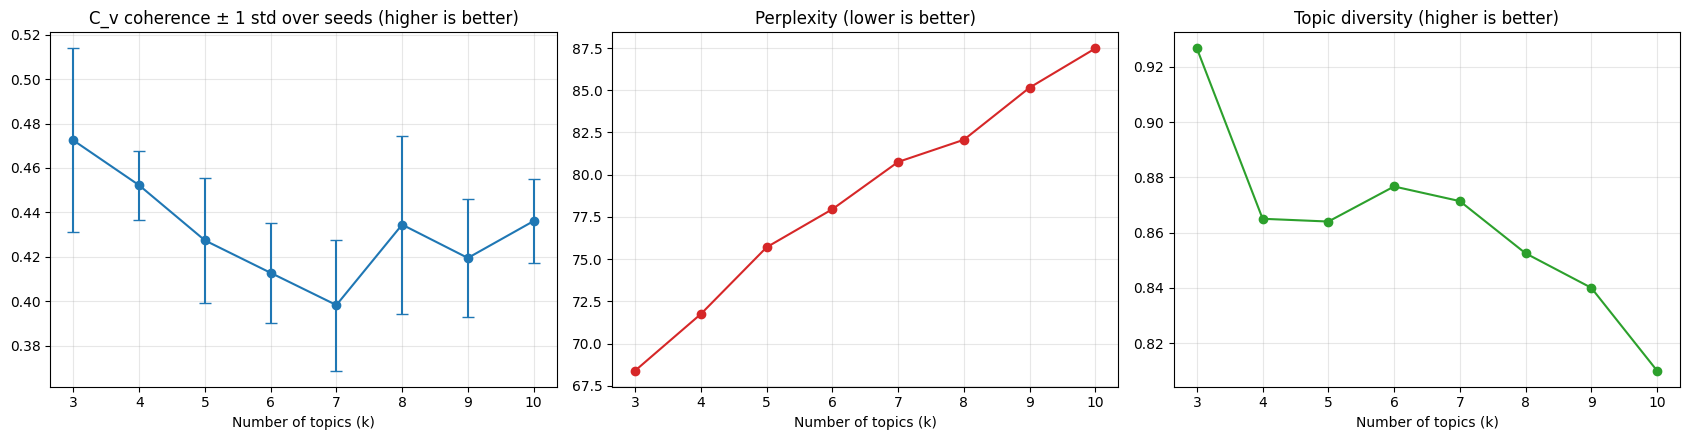

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].errorbar(k_summary.index, k_summary["c_v_mean"], yerr=k_summary["c_v_std"], marker="o", capsize=4)
axes[0].set_title("C_v coherence ± 1 std over seeds (higher is better)")
axes[1].plot(k_summary.index, k_summary["perplexity_mean"], marker="o", color="tab:red")
axes[1].set_title("Perplexity (lower is better)")
axes[2].plot(k_summary.index, k_summary["diversity_mean"], marker="o", color="tab:green")
axes[2].set_title("Topic diversity (higher is better)")
for ax in axes:
    ax.set_xlabel("Number of topics (k)")
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Choosing k with the one-standard-error rule:
# coherence on ~160 short records changes a lot between seeds, so a k that is only slightly
# higher on average is not really better. We take the SMALLEST k whose mean C_v is within one
# standard deviation of the best k. Fewer topics are easier to interpret and less likely to overfit.
# If the group decides another k gives clearer topics, set MANUAL_K and explain why in the paper.
MANUAL_K = None

best_k = int(k_summary["c_v_mean"].idxmax())
threshold = k_summary.loc[best_k, "c_v_mean"] - k_summary.loc[best_k, "c_v_std"]
one_se_k = int(k_summary[k_summary["c_v_mean"] >= threshold].index.min())

FINAL_K = MANUAL_K if MANUAL_K is not None else one_se_k
print(f"k with the highest mean C_v: {best_k} (C_v = {k_summary.loc[best_k, 'c_v_mean']:.4f} ± {k_summary.loc[best_k, 'c_v_std']:.4f})")
print(f"One-standard-error threshold: {threshold:.4f}")
print(f"Smallest k above the threshold: {one_se_k}")
print("k used for the final model:", FINAL_K)

# Use the seed that scored best at FINAL_K, so the final model is the strongest of the 3 runs
best_seed = int(k_runs[k_runs["k"] == FINAL_K].sort_values("c_v", ascending=False).iloc[0]["seed"])
print("Seed used:", best_seed)

k with the highest mean C_v: 3 (C_v = 0.4724 ± 0.0414)
One-standard-error threshold: 0.4310
Smallest k above the threshold: 3
k used for the final model: 3
Seed used: 2024


## Step 6 — Final LDA model
We retrain LDA with the chosen k and inspect the top words of each topic, how coherent each topic is, and which records best represent it.

In [ ]:
lda_final = train_lda(FINAL_K, best_seed)
lda_topics = top_words(lda_final, FINAL_K)

cm_final = CoherenceModel(topics=lda_topics, texts=texts, dictionary=dictionary, coherence="c_v", processes=1)
per_topic_cv = cm_final.get_coherence_per_topic()

lda_topic_table = pd.DataFrame({
    "topic": range(FINAL_K),
    "top_10_words": [", ".join(t) for t in lda_topics],
    "c_v_coherence": np.round(per_topic_cv, 4),
})
print(f"Overall C_v coherence: {cm_final.get_coherence():.4f}")
print(f"Topic diversity: {diversity(lda_topics):.4f}")
print(f"Perplexity: {np.exp2(-lda_final.log_perplexity(corpus)):.2f}")
display(lda_topic_table)

Overall C_v coherence: 0.5426
Topic diversity: 0.9000
Perplexity: 68.15


,topic,top_10_words,c_v_coherence
0,0,"deped, teaching, country, chinese, university, big, experience, college, taiwan, limited",0.4292
1,1,"learning, life, exam, class, skill, country, work, way, private, use",0.8559
2,2,"number, question, type, help, college, university, mabait, essay, educational, city",0.3427


In [ ]:
# Dominant topic for each record = the topic with the highest probability
def dominant_topic(model, bow):
    dist = model.get_document_topics(bow, minimum_probability=0)
    topic, prob = max(dist, key=lambda x: x[1])
    return topic, prob

_dom = [dominant_topic(lda_final, b) for b in corpus]
df_tm["lda_topic"] = [int(t) for t, _ in _dom]
df_tm["lda_topic_prob"] = [float(p) for _, p in _dom]

print("Records per topic:")
display(df_tm["lda_topic"].value_counts().sort_index().to_frame("records"))

# The 3 records that most strongly belong to each topic. Read these to give each topic a label.
for t in range(FINAL_K):
    print(f"\n=== Topic {t}: {', '.join(lda_topics[t][:8])}")
    sample = df_tm[df_tm["lda_topic"] == t].nlargest(3, "lda_topic_prob")
    for _, r in sample.iterrows():
        print(f"  [{r['lda_topic_prob']:.2f}] ({r['platform']}) {r['analysis_text'][:200]}")

Records per topic:


,records
lda_topic,
0,56
1,61
2,35



=== Topic 0: deped, teaching, country, chinese, university, big, experience, college
  [1.00] (reddit) remember one of the metrics methodology used in the international rankings is research output the more advanced the country is the bigger their budget is for their higher education our premier state u
  [0.99] (reddit) it's tough because even taiwanese business people in china have to adapt and use simplified chinese instead of traditional characters simplified chinese is pretty much the lingua franca if you want to
  [0.99] (reddit) so basically teachers who taught chinese used to be local fil chi the problem is there's not as many young fil chi people going into teaching the older ones who stay eventually have to retire so there

=== Topic 1: learning, life, exam, class, skill, country, work, way
  [1.00] (reddit) honestly what frustrates me the most about philippine schools isn t just one thing it s the system as a whole compared to worldwide best practices both public and private

In [ ]:
# TODO (group): after reading the top words and sample records above, replace these with
# short human labels, e.g. {0: "Tuition & college costs", 1: "Teachers & DepEd", ...}
TOPIC_LABELS = {t: f"Topic {t}" for t in range(FINAL_K)}

df_tm["lda_topic_label"] = df_tm["lda_topic"].map(TOPIC_LABELS)
lda_topic_table["label"] = lda_topic_table["topic"].map(TOPIC_LABELS)
display(lda_topic_table[["topic", "label", "top_10_words", "c_v_coherence"]])

,topic,label,top_10_words,c_v_coherence
0,0,Topic 0,"deped, teaching, country, chinese, university, big, experience, college, taiwan, limited",0.4292
1,1,Topic 1,"learning, life, exam, class, skill, country, work, way, private, use",0.8559
2,2,Topic 2,"number, question, type, help, college, university, mabait, essay, educational, city",0.3427


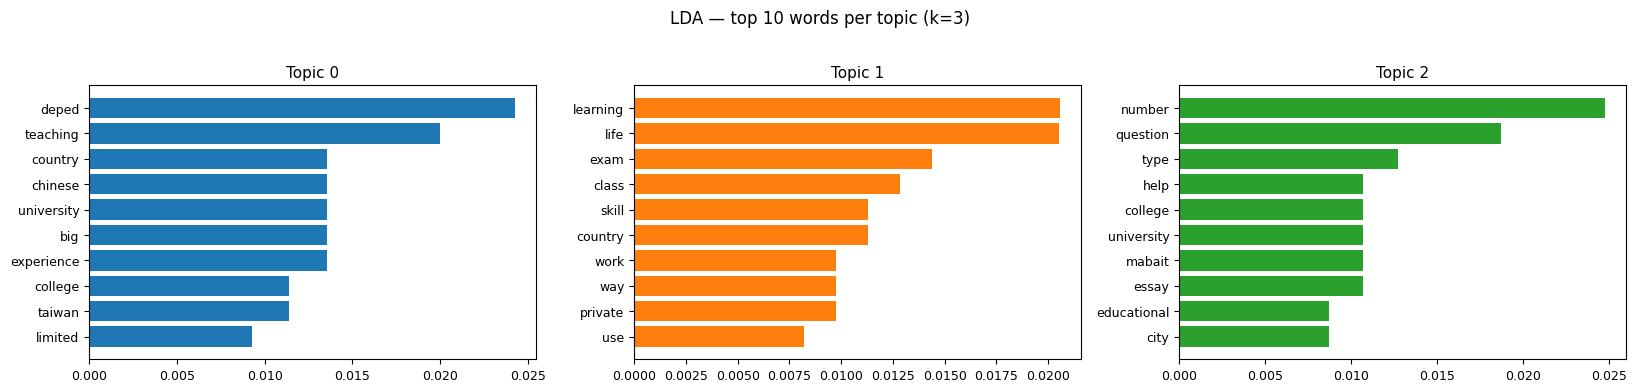

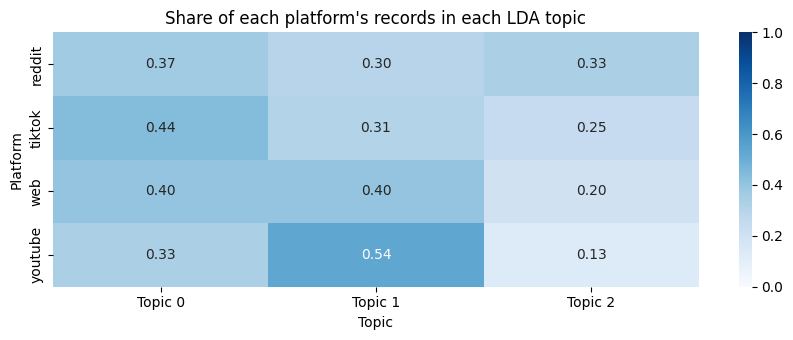

In [ ]:
# Top words per topic (bar charts)
cols = min(FINAL_K, 3)
rows_ = int(np.ceil(FINAL_K / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(5.5 * cols, 3.8 * rows_), squeeze=False)
for t in range(FINAL_K):
    ax = axes[t // cols][t % cols]
    words, weights = zip(*lda_final.show_topic(t, topn=TOPN))
    ax.barh(words[::-1], weights[::-1], color=sns.color_palette("tab10")[t % 10])
    ax.set_title(TOPIC_LABELS[t], fontsize=11)
    ax.tick_params(labelsize=9)
for j in range(FINAL_K, rows_ * cols):
    axes[j // cols][j % cols].axis("off")
plt.suptitle(f"LDA — top {TOPN} words per topic (k={FINAL_K})", y=1.02)
plt.tight_layout()
plt.show()

# Topic share by platform
ct = pd.crosstab(df_tm["platform"], df_tm["lda_topic_label"], normalize="index").round(3)
plt.figure(figsize=(1.6 * FINAL_K + 4, 3.5))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Share of each platform's records in each LDA topic")
plt.ylabel("Platform"); plt.xlabel("Topic")
plt.tight_layout()
plt.show()

In [ ]:
# Interactive topic map (optional). If pyLDAvis fails in your Colab version, skip this cell.
try:
    import pyLDAvis, pyLDAvis.gensim_models
    pyLDAvis.enable_notebook()
    display(pyLDAvis.gensim_models.prepare(lda_final, corpus, dictionary, sort_topics=False))
except Exception as e:
    print("pyLDAvis skipped:", e)

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.110991 -0.052776       1        1  27.517807
1     -0.111943 -0.051441       2        1  42.189677
2      0.000952  0.104218       3        1  30.292516, topic_info=                  Term       Freq      Total Category  logprob  loglift
291             number   9.000000   9.000000  Default  30.0000  30.0000
0                deped  10.000000  10.000000  Default  29.0000  29.0000
55            question   7.000000   7.000000  Default  28.0000  28.0000
70            learning  11.000000  11.000000  Default  27.0000  27.0000
22                life  11.000000  11.000000  Default  26.0000  26.0000
..                 ...        ...        ...      ...      ...      ...
23                need   2.509003   5.320401   Topic3  -5.0087   0.4426
1              digital   2.509046   5.364587   Topic3  -5.0087   0.4344
59            teaching   3.259291  11.956924   Topic3  -4.7471  -0.1055
157  critical_thinking   2.508954   6.248156   Topic3  -5.0087   0.2818
131              class   2.508927  10.205079   Topic3  -5.0087  -0.2088

[182 rows x 6 columns], token_table=      Topic      Freq       Term
term                            
84        2  0.762197     actual
84        3  0.254066     actual
236       3  0.881631  admission
4         2  0.632665     angara
4         3  0.210888     angara
...     ...       ...        ...
75        2  0.583510       work
75        3  0.233404       work
343       1  0.531965      young
343       2  0.265983      young
234       1  0.899681     zhuyin

[223 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Step 7 — LSA (comparison model)
LSA applies SVD (singular value decomposition) to the TF-IDF matrix. Unlike LDA, it is not a probability model: its word weights can be negative, and it has no perplexity. We sweep k the same way (one run per k is enough because LSA is deterministic), then compare it with LDA at **the same k** so the comparison is fair.

In [ ]:
tfidf = TfidfModel(corpus)
corpus_tfidf = tfidf[corpus]

def lsa_top_words(model, k, topn=TOPN):
    # show_topic ranks words by absolute weight; we keep the word and drop the sign
    return [[w for w, _ in model.show_topic(t, topn=topn)] for t in range(k)]

lsa_rows = []
for k in K_RANGE:
    lsa = LsiModel(corpus_tfidf, id2word=dictionary, num_topics=k, random_seed=SEED)
    topics = lsa_top_words(lsa, k)
    lsa_rows.append({"k": k, "c_v": coherence(topics, "c_v"),
                     "u_mass": coherence(topics, "u_mass"), "diversity": diversity(topics)})
lsa_summary = pd.DataFrame(lsa_rows).set_index("k").round(4)
display(lsa_summary)

lsa_final = LsiModel(corpus_tfidf, id2word=dictionary, num_topics=FINAL_K, random_seed=SEED)
lsa_topics = lsa_top_words(lsa_final, FINAL_K)
lsa_topic_table = pd.DataFrame({
    "topic": range(FINAL_K),
    "top_10_words (signed weight)": [
        ", ".join(f"{w}({v:+.2f})" for w, v in lsa_final.show_topic(t, topn=TOPN)) for t in range(FINAL_K)],
})
print(f"\nLSA with k={FINAL_K}: C_v = {coherence(lsa_topics, 'c_v'):.4f}, diversity = {diversity(lsa_topics):.4f}")
display(lsa_topic_table)

# Dominant LSA topic = the dimension with the largest absolute score
def lsa_dominant(vec):
    return max(vec, key=lambda x: abs(x[1]))[0] if vec else -1
df_tm["lsa_topic"] = [lsa_dominant(lsa_final[b]) for b in corpus_tfidf]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,c_v,u_mass,diversity
k,,,
3,0.4425,-14.2953,0.8333
4,0.4440,-15.2596,0.7250
5,0.4460,-15.8080,0.6400
6,0.4432,-16.5008,0.6167
7,0.4493,-16.5668,0.6000
8,0.4400,-16.6125,0.5625
9,0.4440,-16.9307,0.5333
10,0.4291,-16.8209,0.5200



LSA with k=3: C_v = 0.4425, diversity = 0.8333


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,topic,top_10_words (signed weight)
0,0,"deped(-0.88), south(-0.14), lesson(-0.13), teaching(-0.13), exam(-0.12), mekaniko(-0.11), board(-0.11), maganda(-0.1..."
1,1,"big(-0.94), report(-0.20), nasa(-0.19), saying(-0.16), link(-0.04), deped(+0.04), university(-0.03), story(-0.03), s..."
2,2,"university(-0.44), deped(+0.25), chinese(-0.21), teaching(-0.18), country(-0.17), class(-0.16), quality(-0.15), lear..."


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Step 8 — BERTopic (comparison model)
BERTopic turns each record into a sentence embedding, groups similar embeddings (UMAP + HDBSCAN), and then describes each group by its most distinctive words (c-TF-IDF).
- We use **`paraphrase-multilingual-MiniLM-L12-v2`**, which understands English, Tagalog, and Taglish.
- The embeddings are made from the **cleaned full sentences**, not the stopword-removed tokens, because the model needs natural sentences. The stopword list is applied only when choosing the topic words.
- Records that don't fit any group are labeled **topic −1 (outliers)**. We report the outlier percentage.
- With fewer than 200 short records, BERTopic tends to find only a few clusters, which is something to discuss when comparing the models.

In [ ]:
bertopic_ok = False
try:
    from bertopic import BERTopic
    from sentence_transformers import SentenceTransformer
    from umap import UMAP
    from hdbscan import HDBSCAN
    from sklearn.feature_extraction.text import CountVectorizer

    # Set to a number (e.g. FINAL_K) to merge BERTopic's clusters down to that many topics; None = let it decide
    BT_NR_TOPICS = None

    bt_docs = df_tm["analysis_text"].apply(clean_text).tolist()
    embedder = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
    embeddings = embedder.encode(bt_docs, show_progress_bar=True)

    topic_model = BERTopic(
        embedding_model=embedder,
        umap_model=UMAP(n_neighbors=10, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
        hdbscan_model=HDBSCAN(min_cluster_size=5, min_samples=2, metric="euclidean", prediction_data=True),
        vectorizer_model=CountVectorizer(stop_words=list(STOPWORDS), token_pattern=r"(?u)\b[a-zñ]{3,}\b"),
        top_n_words=TOPN,
        nr_topics=(BT_NR_TOPICS + 1) if BT_NR_TOPICS else None,   # +1 because the outlier group counts as a topic
    )
    bt_topics, _ = topic_model.fit_transform(bt_docs, embeddings)
    df_tm["bertopic_topic"] = bt_topics

    bt_info = topic_model.get_topic_info()
    display(bt_info[["Topic", "Count", "Name"]])

    n_bt_topics = len([t for t in bt_info["Topic"] if t != -1])
    outlier_pct = (np.array(bt_topics) == -1).mean() * 100
    print(f"BERTopic found {n_bt_topics} topics; {outlier_pct:.1f}% of records are outliers (topic -1)")

    # Coherence: keep topic words that are in our LDA dictionary so all models are scored the same way
    bt_topic_words = []
    for t in bt_info["Topic"]:
        if t == -1:
            continue
        words = [w for w, _ in topic_model.get_topic(t) if w in dictionary.token2id]
        if len(words) >= 2:
            bt_topic_words.append(words)
    bt_cv = coherence(bt_topic_words, "c_v") if len(bt_topic_words) >= 2 else np.nan
    bt_umass = coherence(bt_topic_words, "u_mass") if len(bt_topic_words) >= 2 else np.nan
    bt_div = diversity(bt_topic_words) if bt_topic_words else np.nan
    print(f"BERTopic C_v = {bt_cv:.4f}, diversity = {bt_div:.4f}")
    bertopic_ok = True
except Exception as e:
    print("BERTopic step failed:", repr(e))
    print("The LDA and LSA results above are still valid; re-run this cell after fixing the install.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

...

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Topic,Count,Name
0,-1,18,-1_bpo_college_scholar_pbbm
1,0,31,0_students_universities_private_classes
2,1,23,1_thinking_questions_students_work
3,2,18,2_number_graham_large_big
4,3,13,3_character_content_bayombong_room
5,4,9,4_tuition_gains_pisa_voucher
6,5,8,5_salita_gobyerno_agad_pwedeng
7,6,8,6_chinese_taiwan_teaching_china
8,7,7,7_anak_point_pinangunahan_course
9,8,6,8_deped_teachers_banga_campaign


BERTopic found 11 topics; 11.8% of records are outliers (topic -1)
BERTopic C_v = 0.4613, diversity = 0.9792


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
if bertopic_ok and n_bt_topics >= 2:
    display(topic_model.visualize_barchart(top_n_topics=min(n_bt_topics, 8), n_words=8))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

## Step 9 — Model comparison
All three models are scored with the same dictionary and the same coherence measures. LDA and LSA use the same k. BERTopic decides its own number of topics.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

,model,num_topics,c_v,u_mass,diversity,perplexity,outliers_%
0,LDA,3,0.5426,-10.8493,0.9000,68.1499,0.0000
1,LSA,3,0.4425,-14.2953,0.8333,NaN,0.0000
2,BERTopic,11,0.4613,-11.8930,0.9792,NaN,11.8421


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

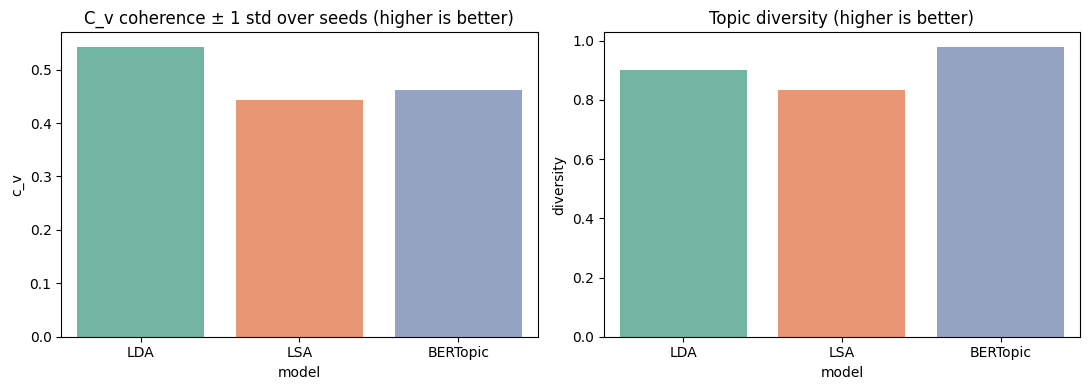

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

In [ ]:
comparison = [
    {"model": "LDA", "num_topics": FINAL_K,
     "c_v": coherence(lda_topics, "c_v"), "u_mass": coherence(lda_topics, "u_mass"),
     "diversity": diversity(lda_topics), "perplexity": np.exp2(-lda_final.log_perplexity(corpus)),
     "outliers_%": 0.0},
    {"model": "LSA", "num_topics": FINAL_K,
     "c_v": coherence(lsa_topics, "c_v"), "u_mass": coherence(lsa_topics, "u_mass"),
     "diversity": diversity(lsa_topics), "perplexity": np.nan, "outliers_%": 0.0},
]
if bertopic_ok:
    comparison.append({"model": "BERTopic", "num_topics": n_bt_topics, "c_v": bt_cv, "u_mass": bt_umass,
                       "diversity": bt_div, "perplexity": np.nan, "outliers_%": outlier_pct})

comparison_df = pd.DataFrame(comparison).round(4)
display(comparison_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=comparison_df, x="model", y="c_v", ax=axes[0], palette="Set2")
axes[0].set_title("C_v coherence ± 1 std over seeds (higher is better)")
sns.barplot(data=comparison_df, x="model", y="diversity", ax=axes[1], palette="Set2")
axes[1].set_title("Topic diversity (higher is better)")
plt.tight_layout()
plt.show()

## Step 10 — Assign topics to the holdout set and save the results
The topic assignments are saved so the sentiment analysis can report **sentiment per topic**.

In [ ]:
os.makedirs("topic_modeling_outputs", exist_ok=True)
out = "topic_modeling_outputs/"

keep_cols = ["record_id", "platform", "record_type", "keyword", "analysis_text",
             "lda_topic", "lda_topic_label", "lda_topic_prob", "lsa_topic"]
if bertopic_ok:
    keep_cols.append("bertopic_topic")
df_tm[keep_cols].to_csv(out + "topic_assignments_train.csv", index=False)

if holdout_df is not None:
    holdout_df["tokens_tm"] = holdout_df["analysis_text"].apply(tokenize).apply(lambda t: bigram[t])
    hold_bow = [dictionary.doc2bow(t) for t in holdout_df["tokens_tm"]]
    _hd = [dominant_topic(lda_final, b) if b else (-1, 0.0) for b in hold_bow]
    holdout_df["lda_topic"] = [int(t) for t, _ in _hd]
    holdout_df["lda_topic_prob"] = [float(p) for _, p in _hd]
    holdout_df["lda_topic_label"] = holdout_df["lda_topic"].map(TOPIC_LABELS).fillna("Unassigned")
    holdout_df[["record_id", "platform", "analysis_text", "lda_topic", "lda_topic_label", "lda_topic_prob"]] \
        .to_csv(out + "topic_assignments_holdout.csv", index=False)
    print("Holdout topic counts:")
    display(holdout_df["lda_topic_label"].value_counts())

k_runs.to_csv(out + "lda_k_selection_all_runs.csv", index=False)
k_summary.to_csv(out + "lda_k_selection_summary.csv")
lsa_summary.to_csv(out + "lsa_k_selection_summary.csv")
lda_topic_table.to_csv(out + "lda_topics.csv", index=False)
lsa_topic_table.to_csv(out + "lsa_topics.csv", index=False)
comparison_df.to_csv(out + "model_comparison.csv", index=False)
if bertopic_ok:
    bt_info.drop(columns=["Representative_Docs"], errors="ignore").to_csv(out + "bertopic_topics.csv", index=False)
lda_final.save(out + "lda_final.model")

print("Saved:", sorted(os.listdir(out)))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

Holdout topic counts:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,count
lda_topic_label,
Topic 1,8
Topic 0,6
Unassigned,3
Topic 2,2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



Saved: ['bertopic_topics.csv', 'lda_final.model', 'lda_final.model.expElogbeta.npy', 'lda_final.model.id2word', 'lda_final.model.state', 'lda_k_selection_all_runs.csv', 'lda_k_selection_summary.csv', 'lda_topics.csv', 'lsa_k_selection_summary.csv', 'lsa_topics.csv', 'model_comparison.csv', 'topic_assignments_holdout.csv', 'topic_assignments_train.csv']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

In [ ]:
# Download all outputs as one zip (Colab only)
try:
    import shutil
    from google.colab import files
    shutil.make_archive("topic_modeling_outputs", "zip", "topic_modeling_outputs")
    files.download("topic_modeling_outputs.zip")
except ImportError:
    print("Not running in Colab; outputs are in ./topic_modeling_outputs/")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

## Notes for the paper (Script / Output / Remarks table)
Points to cover in the remarks and the discussion:
- **Choosing k:** report the k-selection table and the 3 plots. Explain the one-standard-error rule (the smallest k whose average C_v over 5 seeds is within one standard deviation of the best), and say whether the topics at that k were readable. If you used `MANUAL_K`, explain why.
- **Topic interpretation:** for each LDA topic, give its label, its top words, its per-topic coherence, and 1–2 example records.
- **Evaluation:** C_v coherence above about 0.4 is usually acceptable and above 0.5 is good for short social-media text. Perplexity is supporting evidence only.
- **Comparison:** LDA vs LSA at the same k, and BERTopic with its own k and its outlier %. Explain why the winner won. For example, LSA's negative weights make its topics harder to label, and BERTopic needs more data than ~180 short records.
- **Limitations:** the dataset is small, the texts are short, articles are represented by titles only, and the posts mix languages.